<a href="https://colab.research.google.com/github/huseyinTozluyurt/Flyrank-Internship-MachineLearning/blob/main/notebooks/ContentRefreshRecommendationEngine/FlyRank_Content_Refresh_Recommendation_Engine_Stage2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# FlyRank — Content Refresh Recommendation Engine
## Stage 2.1: validated LambdaRank, data coverage, and actionable recommendations

This notebook revises the Stage 2 LambdaRank prototype. It keeps the DuckDB + Hugging Face warehouse workflow and the existing LightGBM ranking objective, while adding:

1. GSC availability and missing-measurement audits; missing metrics are **not converted to zero**.
2. Conservative target eligibility based on observed content-day coverage.
3. Stable logarithmic trend features and CTR missingness diagnostics.
4. Reproducible, relevance-stratified sampling for **training groups only** when a client exceeds the configurable group cap. Test groups remain unsampled.
5. Repeated client-level holdout evaluation with NDCG@5/@10 distributions.
6. Evidence-based recommendation eligibility and HIGH-priority rules.
7. Optional, schema-aware joins to `dim_content` metadata and `fact_query_90d` query signals.

### Important interpretation
The target remains a proxy: future impression decline severity, not observed refresh uplift. Query-signal tables may not be aligned to the historical feature cutoff, so they are joined for **recommendation context only** and are not used as training features. Confirm their date semantics before including them in a future model.

Run top-to-bottom in Google Colab. This notebook is syntax/structure checked, but has not been executed against your authenticated Hugging Face warehouse in this session.

In [1]:
%pip -q install duckdb huggingface_hub pandas numpy matplotlib seaborn scikit-learn lightgbm joblib

## 1. Authenticate to Hugging Face

In Colab, add `HF_TOKEN` under **Secrets** and enable notebook access. The fallback prompt is hidden input. Never hard-code the token or share it in chat.

In [2]:
import os
from getpass import getpass

HF_TOKEN = os.environ.get("HF_TOKEN")
if not HF_TOKEN:
    try:
        from google.colab import userdata
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None
if not HF_TOKEN:
    HF_TOKEN = getpass("Hugging Face token (input hidden): ")
if not HF_TOKEN:
    raise RuntimeError("HF_TOKEN is required to access the private dataset.")
print("Hugging Face token loaded.")

Hugging Face token (input hidden): ··········
Hugging Face token loaded.


In [3]:
import duckdb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import SimpleImputer
from sklearn.model_selection import GroupShuffleSplit
from lightgbm import LGBMRanker
import joblib
import warnings
import json
from pathlib import Path

con = duckdb.connect()
safe_token = HF_TOKEN.replace("'", "''")
con.execute(f"CREATE OR REPLACE SECRET hf (TYPE huggingface, TOKEN '{safe_token}')")

REL = "hf://datasets/FlyRank/internship-warehouse"
TABLES = {
    "dim_clients": f"read_parquet('{REL}/dim_clients.parquet')",
    "dim_content": f"read_parquet('{REL}/dim_content.parquet')",
    "fact_daily": f"read_parquet('{REL}/fact_content_daily_performance/**/*.parquet')",
    "fact_daily_sample": f"read_parquet('{REL}/fact_content_daily_performance_sample.parquet')",
    "fact_query_90d": f"read_parquet('{REL}/fact_content_query_90d.parquet')",
}
print("DuckDB connected; warehouse paths configured.")

DuckDB connected; warehouse paths configured.


## 2. Inspect schema and date coverage

The notebook discovers optional metadata/query columns at runtime. It requires the identifiers, report date, GSC availability flag, impressions, clicks, and average position. If the warehouse schema differs, the notebook stops instead of silently substituting fields.

In [4]:
schemas = {}
for table_name, source_sql in TABLES.items():
    try:
        schemas[table_name] = con.execute(f"DESCRIBE SELECT * FROM {source_sql}").df()
        print(f"{table_name}: {len(schemas[table_name])} columns")
    except Exception as exc:
        if table_name in {"dim_content", "fact_query_90d", "dim_clients", "fact_daily_sample"}:
            warnings.warn(f"Optional table {table_name} could not be inspected: {exc}")
        else:
            raise

daily_columns = set(schemas["fact_daily"]["column_name"])
display(schemas["fact_daily"])
required = {
    "report_date", "client_hash_id", "content_hash_id",
    "gsc_data_available", "gsc_impressions", "gsc_clicks", "gsc_avg_position"
}
missing = required - daily_columns
if missing:
    raise ValueError(f"Required columns missing from fact_daily: {sorted(missing)}")

date_coverage = con.execute(f'''
SELECT MIN(report_date) AS min_report_date,
       MAX(report_date) AS max_report_date,
       COUNT(*) AS raw_rows,
       COUNT(DISTINCT client_hash_id) AS clients,
       COUNT(DISTINCT content_hash_id) AS content_ids
FROM {TABLES["fact_daily"]}
''').df()
display(date_coverage)

dim_clients: 9 columns
dim_content: 26 columns
fact_daily: 31 columns
fact_daily_sample: 31 columns
fact_query_90d: 21 columns


,column_name,column_type,null,key,default,extra
0,report_date,DATE,YES,None,None,None
1,client_hash_id,VARCHAR,YES,None,None,None
2,content_hash_id,VARCHAR,YES,None,None,None
3,client_has_gsc,BOOLEAN,YES,None,None,None
4,client_has_ga4,BOOLEAN,YES,None,None,None
5,gsc_data_available,BOOLEAN,YES,None,None,None
6,ga4_data_available,BOOLEAN,YES,None,None,None
7,gsc_impressions,BIGINT,YES,None,None,None
8,gsc_clicks,BIGINT,YES,None,None,None
9,gsc_sum_position,BIGINT,YES,None,None,None


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,min_report_date,max_report_date,raw_rows,clients,content_ids
0,2025-01-27,2026-06-30,78835655,70,427292


## 3. Audit GSC availability, missing measurements, and duplicate keys — optimized

The previous version scanned the remote Parquet source separately for the availability audit, duplicate-key audit, and per-client coverage audit. The duplicate-key query also performed a costly `COUNT(DISTINCT struct)` across the full recent window.

This version:
1. Reads only the columns needed for these checks.
2. Creates one temporary, 120-day audit table and reuses it for all diagnostics.
3. Checks duplicate keys in two passes: first count duplicate keys; then check conflicting values only within duplicated keys.
4. Avoids a full per-client date-distinct report by summarizing coverage from the cached audit table.

The initial maximum-date lookup still requires DuckDB to inspect the remote dataset. If the source is partitioned by date, partition pruning may further improve performance; verify this from the dataset's actual file layout.

In [5]:
# Configure DuckDB conservatively for Colab. Set memory_limit below the runtime's RAM.
import os
from time import perf_counter

duckdb_threads = max(1, (os.cpu_count() or 2) - 1)
con.execute(f"SET threads = {duckdb_threads}")
con.execute("SET preserve_insertion_order = false")
# If this runtime has 12+ GB RAM, 8GB is a reasonable starting point.
# Lower this value if the runtime has less memory.
con.execute("SET memory_limit = '8GB'")

audit_started = perf_counter()

# Determine the latest date once. The following table is then reused for all audits.
audit_end_date = con.execute(
    f"SELECT MAX(report_date) FROM {TABLES['fact_daily']}"
).fetchone()[0]
if audit_end_date is None:
    raise ValueError("No report_date values were found in fact_daily.")

print("Latest report date:", audit_end_date)
print("DuckDB threads:", duckdb_threads)

# Use a narrow projection and retain source rows for the duplicate checks.
# Do not DISTINCT here: we need to distinguish identical duplicates from conflicts.
con.execute("DROP TABLE IF EXISTS stage21_audit_daily")
con.execute(f"""
CREATE TEMP TABLE stage21_audit_daily AS
SELECT
    report_date,
    client_hash_id,
    content_hash_id,
    gsc_data_available,
    gsc_impressions,
    gsc_clicks,
    gsc_avg_position
FROM {TABLES["fact_daily"]}
WHERE report_date > ? - INTERVAL 120 DAY
""", [audit_end_date])

print(f"Cached 120-day audit rows: {con.execute('SELECT COUNT(*) FROM stage21_audit_daily').fetchone()[0]:,}")
print(f"Initial scan and cache time: {perf_counter() - audit_started:.1f} seconds")

# Availability and missingness summary from the cached table (no remote Parquet scan).
availability_audit = con.execute("""
SELECT
    CASE
      WHEN gsc_data_available IS TRUE THEN 'available_true'
      WHEN gsc_data_available IS FALSE THEN 'available_false'
      ELSE 'availability_null'
    END AS gsc_availability_status,
    COUNT(*) AS rows,
    COUNT(*) FILTER (WHERE gsc_impressions IS NULL) AS impressions_null_rows,
    COUNT(*) FILTER (WHERE gsc_clicks IS NULL) AS clicks_null_rows,
    COUNT(*) FILTER (WHERE gsc_avg_position IS NULL) AS position_null_rows,
    COUNT(*) FILTER (WHERE gsc_impressions = 0) AS explicit_zero_impression_rows,
    COUNT(*) FILTER (WHERE gsc_data_available IS TRUE AND gsc_impressions IS NULL)
        AS available_but_impressions_missing
FROM stage21_audit_daily
GROUP BY 1
ORDER BY 1
""").df()
display(availability_audit)

# First pass: find duplicate key groups without expensive distinct-struct aggregation.
duplicate_groups = con.execute("""
CREATE OR REPLACE TEMP TABLE stage21_duplicate_keys AS
SELECT
    report_date, client_hash_id, content_hash_id, COUNT(*) AS n_rows
FROM stage21_audit_daily
GROUP BY report_date, client_hash_id, content_hash_id
HAVING COUNT(*) > 1
""")
duplicate_key_counts = con.execute("""
SELECT
    COUNT(*) AS duplicate_key_groups,
    COALESCE(SUM(n_rows - 1), 0) AS excess_rows_in_duplicate_groups
FROM stage21_duplicate_keys
""").df()

# Second pass: compare values only for duplicate keys. Hash the selected GSC fields
# to avoid materializing a large DISTINCT struct; nulls are represented explicitly.
duplicate_conflicts = con.execute("""
WITH versions AS (
    SELECT
        d.report_date,
        d.client_hash_id,
        d.content_hash_id,
        COUNT(DISTINCT hash(
            coalesce(CAST(d.gsc_data_available AS VARCHAR), '<NULL>'),
            coalesce(CAST(d.gsc_impressions AS VARCHAR), '<NULL>'),
            coalesce(CAST(d.gsc_clicks AS VARCHAR), '<NULL>'),
            coalesce(CAST(d.gsc_avg_position AS VARCHAR), '<NULL>')
        )) AS distinct_gsc_versions
    FROM stage21_audit_daily d
    INNER JOIN stage21_duplicate_keys k
      USING (report_date, client_hash_id, content_hash_id)
    GROUP BY 1, 2, 3
)
SELECT
    COUNT(*) FILTER (WHERE distinct_gsc_versions = 1) AS exact_duplicate_key_groups,
    COUNT(*) FILTER (WHERE distinct_gsc_versions > 1) AS conflicting_duplicate_key_groups
FROM versions
""").df()

duplicate_key_audit = duplicate_key_counts.join(duplicate_conflicts)
display(duplicate_key_audit)

# Per-client availability summary from the same cached table.
availability_by_client = con.execute("""
SELECT
    client_hash_id,
    COUNT(DISTINCT report_date) AS dates_with_rows,
    COUNT(DISTINCT CASE WHEN gsc_data_available IS TRUE THEN report_date END) AS dates_gsc_available,
    COUNT(DISTINCT CASE WHEN gsc_data_available IS FALSE THEN report_date END) AS dates_gsc_unavailable,
    COUNT(DISTINCT CASE WHEN gsc_data_available IS NULL THEN report_date END) AS dates_gsc_status_unknown
FROM stage21_audit_daily
GROUP BY client_hash_id
ORDER BY dates_gsc_available DESC
""").df()
display(availability_by_client.head(20))
print(f"Section 3 audit completed in {perf_counter() - audit_started:.1f} seconds.")


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Latest report date: 2026-06-30
DuckDB threads: 1


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Cached 120-day audit rows: 43,095,413
Initial scan and cache time: 351.0 seconds


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

...

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,duplicate_key_groups,excess_rows_in_duplicate_groups,exact_duplicate_key_groups,conflicting_duplicate_key_groups
0,6390,6390.0,6390,0


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,client_hash_id,dates_with_rows,dates_gsc_available,dates_gsc_unavailable,dates_gsc_status_unknown
0,client_65de48885f4ef01b,120,120,120,0
1,client_c182d11e4862a37d,120,120,120,0
2,client_400c21c81c8b46ef,120,120,120,0
3,client_08a6a72ff48e62c0,120,120,120,0
4,client_23a62021009f63c4,120,120,120,0
5,client_62f4a7e64f5e0096,120,120,120,0
6,client_3ffa76342f366962,120,120,120,0
7,client_9958f0a7ae1df715,120,120,120,0
8,client_73cda7b4e4f265ea,120,120,120,0
9,client_3197e6291363b4db,120,120,115,0


Section 3 audit completed in 408.8 seconds.


### Coverage policy

For target labels, a client-content pair must have at least `MIN_TARGET_OBSERVED_DAYS` distinct days with `gsc_data_available = TRUE` and non-null impressions in each 30-day target window. Missing target impressions are not filled with zero. Exact repeated GSC observations are flagged and can be deduplicated during feature aggregation; conflicting observations for the same client/content/date must be resolved at source.

In [6]:
MIN_TARGET_OBSERVED_DAYS = 15
MIN_FEATURE_OBSERVED_DAYS = 15
MIN_PREV_TARGET_IMPRESSIONS = 100
MIN_RECOMMENDATION_FEATURE_IMPRESSIONS = 100
MIN_RECOMMENDATION_FEATURE_DAYS = 21
MAX_TRAIN_GROUP_SIZE = 10_000
RANDOM_SEEDS = [11, 23, 42, 61, 97]
TEST_SIZE = 0.20

conflicting_groups = int(duplicate_key_audit.loc[0, "conflicting_duplicate_key_groups"])
exact_duplicate_groups = int(duplicate_key_audit.loc[0, "exact_duplicate_key_groups"])

if exact_duplicate_groups:
    print(
        f"Found {exact_duplicate_groups:,} duplicate key groups with identical GSC values. "
        "Section 4 should deduplicate exact copies before aggregation."
    )

if conflicting_groups > 0:
    print(
        f"ERROR: {conflicting_groups:,} client-content-date groups have conflicting GSC values. "
        "The notebook stops before training rather than guessing whether the records should be summed."
    )
    raise ValueError(
        "Conflicting duplicate (client_hash_id, content_hash_id, report_date) GSC observations. "
        "Inspect duplicate_key_audit and resolve the source records."
    )


Found 6,390 duplicate key groups with identical GSC values. Section 4 should deduplicate exact copies before aggregation.


## 4. Build training examples with coverage-aware SQL — optimized

The original Section 4 query scanned the remote Parquet dataset again, calculated `MAX(report_date)` again, applied a wide `SELECT DISTINCT`, and ran many `COUNT(DISTINCT report_date)` aggregates. Section 3 has already created `stage21_audit_daily`, checked duplicate keys, and confirmed whether duplicate rows conflict.

This version reuses the Section 3 temporary table, removes only exact duplicate GSC observations, and uses conditional `COUNT(*)` for observed-day counts after de-duplication. That avoids another remote warehouse scan and reduces expensive distinct aggregations. It preserves the availability checks and coverage thresholds.

The first run still has to download and cache the 120-day source window in Section 3. If the cache itself is too large for Colab RAM/disk, the next step is to use date-partition pruning or persist a local Parquet cache rather than switch to a GPU.

In [7]:
rank_sql = f'''
WITH bounds AS (
    -- Reuse the max date already discovered and cached in Section 3.
    SELECT MAX(report_date) AS end_d FROM stage21_audit_daily
),
daily_source AS (
    -- Section 3 established that duplicate keys are either exact copies or conflicting.
    -- Conflicting records stop execution. DISTINCT here therefore removes only exact copies.
    -- Crucially, this reads the cached temporary table, not remote Hugging Face Parquet files.
    SELECT DISTINCT
        report_date,
        client_hash_id,
        content_hash_id,
        gsc_data_available,
        gsc_impressions,
        gsc_clicks,
        gsc_avg_position
    FROM stage21_audit_daily
),
agg AS (
    SELECT
        f.client_hash_id,
        f.content_hash_id,
        MAX(b.end_d) AS data_end_date,

        SUM(CASE WHEN f.report_date > b.end_d - INTERVAL 30 DAY
                       AND f.gsc_data_available IS TRUE
                       AND f.gsc_impressions IS NOT NULL
                 THEN f.gsc_impressions END) AS target_imp_last30_observed_sum,
        SUM(CASE WHEN f.report_date <= b.end_d - INTERVAL 30 DAY
                       AND f.report_date > b.end_d - INTERVAL 60 DAY
                       AND f.gsc_data_available IS TRUE
                       AND f.gsc_impressions IS NOT NULL
                 THEN f.gsc_impressions END) AS target_imp_prev30_observed_sum,

        COUNT(CASE WHEN f.report_date > b.end_d - INTERVAL 30 DAY
                                  AND f.gsc_data_available IS TRUE
                                  AND f.gsc_impressions IS NOT NULL
                            THEN 1 END) AS target_observed_days_last30,
        COUNT(CASE WHEN f.report_date <= b.end_d - INTERVAL 30 DAY
                                  AND f.report_date > b.end_d - INTERVAL 60 DAY
                                  AND f.gsc_data_available IS TRUE
                                  AND f.gsc_impressions IS NOT NULL
                            THEN 1 END) AS target_observed_days_prev30,

        SUM(CASE WHEN f.report_date <= b.end_d - INTERVAL 60 DAY
                       AND f.report_date > b.end_d - INTERVAL 90 DAY
                       AND f.gsc_data_available IS TRUE
                       AND f.gsc_impressions IS NOT NULL
                 THEN f.gsc_impressions END) AS feat_imp_60_90_observed_sum,
        SUM(CASE WHEN f.report_date <= b.end_d - INTERVAL 90 DAY
                       AND f.report_date > b.end_d - INTERVAL 120 DAY
                       AND f.gsc_data_available IS TRUE
                       AND f.gsc_impressions IS NOT NULL
                 THEN f.gsc_impressions END) AS feat_imp_90_120_observed_sum,
        SUM(CASE WHEN f.report_date <= b.end_d - INTERVAL 60 DAY
                       AND f.report_date > b.end_d - INTERVAL 90 DAY
                       AND f.gsc_data_available IS TRUE
                       AND f.gsc_clicks IS NOT NULL
                 THEN f.gsc_clicks END) AS feat_clk_60_90_observed_sum,
        SUM(CASE WHEN f.report_date <= b.end_d - INTERVAL 90 DAY
                       AND f.report_date > b.end_d - INTERVAL 120 DAY
                       AND f.gsc_data_available IS TRUE
                       AND f.gsc_clicks IS NOT NULL
                 THEN f.gsc_clicks END) AS feat_clk_90_120_observed_sum,
        SUM(CASE WHEN f.report_date <= b.end_d - INTERVAL 60 DAY
                       AND f.report_date > b.end_d - INTERVAL 90 DAY
                       AND f.gsc_data_available IS TRUE
                       AND f.gsc_clicks IS NOT NULL
                       AND f.gsc_impressions IS NOT NULL
                 THEN f.gsc_clicks END) AS feat_ctr_clicks_60_90,
        SUM(CASE WHEN f.report_date <= b.end_d - INTERVAL 60 DAY
                       AND f.report_date > b.end_d - INTERVAL 90 DAY
                       AND f.gsc_data_available IS TRUE
                       AND f.gsc_clicks IS NOT NULL
                       AND f.gsc_impressions IS NOT NULL
                 THEN f.gsc_impressions END) AS feat_ctr_impressions_60_90,
        SUM(CASE WHEN f.report_date <= b.end_d - INTERVAL 90 DAY
                       AND f.report_date > b.end_d - INTERVAL 120 DAY
                       AND f.gsc_data_available IS TRUE
                       AND f.gsc_clicks IS NOT NULL
                       AND f.gsc_impressions IS NOT NULL
                 THEN f.gsc_clicks END) AS feat_ctr_clicks_90_120,
        SUM(CASE WHEN f.report_date <= b.end_d - INTERVAL 90 DAY
                       AND f.report_date > b.end_d - INTERVAL 120 DAY
                       AND f.gsc_data_available IS TRUE
                       AND f.gsc_clicks IS NOT NULL
                       AND f.gsc_impressions IS NOT NULL
                 THEN f.gsc_impressions END) AS feat_ctr_impressions_90_120,
        AVG(CASE WHEN f.report_date <= b.end_d - INTERVAL 60 DAY
                       AND f.report_date > b.end_d - INTERVAL 90 DAY
                       AND f.gsc_data_available IS TRUE
                 THEN f.gsc_avg_position END) AS feat_pos_60_90,
        AVG(CASE WHEN f.report_date <= b.end_d - INTERVAL 90 DAY
                       AND f.report_date > b.end_d - INTERVAL 120 DAY
                       AND f.gsc_data_available IS TRUE
                 THEN f.gsc_avg_position END) AS feat_pos_90_120,
        STDDEV_SAMP(CASE WHEN f.report_date <= b.end_d - INTERVAL 60 DAY
                              AND f.report_date > b.end_d - INTERVAL 90 DAY
                              AND f.gsc_data_available IS TRUE
                         THEN f.gsc_avg_position END) AS feat_pos_volatility_60_90,
        COUNT(CASE WHEN f.report_date <= b.end_d - INTERVAL 60 DAY
                                  AND f.report_date > b.end_d - INTERVAL 90 DAY
                                  AND f.gsc_data_available IS TRUE
                                  AND f.gsc_impressions IS NOT NULL
                            THEN 1 END) AS feat_active_days_60_90,
        COUNT(CASE WHEN f.report_date <= b.end_d - INTERVAL 90 DAY
                                  AND f.report_date > b.end_d - INTERVAL 120 DAY
                                  AND f.gsc_data_available IS TRUE
                                  AND f.gsc_impressions IS NOT NULL
                            THEN 1 END) AS feat_active_days_90_120,
        COUNT(CASE WHEN f.report_date <= b.end_d - INTERVAL 60 DAY
                                  AND f.report_date > b.end_d - INTERVAL 90 DAY
                                  AND f.gsc_data_available IS TRUE
                                  AND f.gsc_clicks IS NOT NULL
                            THEN 1 END) AS feat_click_active_days_60_90,
        COUNT(CASE WHEN f.report_date <= b.end_d - INTERVAL 90 DAY
                                  AND f.report_date > b.end_d - INTERVAL 120 DAY
                                  AND f.gsc_data_available IS TRUE
                                  AND f.gsc_clicks IS NOT NULL
                            THEN 1 END) AS feat_click_active_days_90_120,
        COUNT(CASE WHEN f.report_date <= b.end_d - INTERVAL 60 DAY
                                  AND f.report_date > b.end_d - INTERVAL 90 DAY
                                  AND f.gsc_data_available IS TRUE
                                  AND f.gsc_clicks IS NOT NULL
                                  AND f.gsc_impressions IS NOT NULL
                            THEN 1 END) AS feat_ctr_observed_days_60_90,
        COUNT(CASE WHEN f.report_date <= b.end_d - INTERVAL 90 DAY
                                  AND f.report_date > b.end_d - INTERVAL 120 DAY
                                  AND f.gsc_data_available IS TRUE
                                  AND f.gsc_clicks IS NOT NULL
                                  AND f.gsc_impressions IS NOT NULL
                            THEN 1 END) AS feat_ctr_observed_days_90_120
    FROM daily_source f
    CROSS JOIN bounds b
    GROUP BY f.client_hash_id, f.content_hash_id
), normalized AS (
    SELECT *,
        target_imp_last30_observed_sum * 30.0 / NULLIF(target_observed_days_last30, 0) AS target_imp_last30,
        target_imp_prev30_observed_sum * 30.0 / NULLIF(target_observed_days_prev30, 0) AS target_imp_prev30,
        feat_imp_60_90_observed_sum * 30.0 / NULLIF(feat_active_days_60_90, 0) AS feat_imp_60_90,
        feat_imp_90_120_observed_sum * 30.0 / NULLIF(feat_active_days_90_120, 0) AS feat_imp_90_120,
        feat_clk_60_90_observed_sum * 30.0 / NULLIF(feat_click_active_days_60_90, 0) AS feat_clk_60_90,
        feat_clk_90_120_observed_sum * 30.0 / NULLIF(feat_click_active_days_90_120, 0) AS feat_clk_90_120
    FROM agg
)
SELECT *,
    (target_imp_last30 - target_imp_prev30) / NULLIF(target_imp_prev30, 0) AS target_trend_pct,
    CASE
      WHEN (target_imp_last30 - target_imp_prev30) / NULLIF(target_imp_prev30, 0) <= -0.80 THEN 4
      WHEN (target_imp_last30 - target_imp_prev30) / NULLIF(target_imp_prev30, 0) <= -0.60 THEN 3
      WHEN (target_imp_last30 - target_imp_prev30) / NULLIF(target_imp_prev30, 0) <= -0.40 THEN 2
      WHEN (target_imp_last30 - target_imp_prev30) / NULLIF(target_imp_prev30, 0) < -0.20 THEN 1
      ELSE 0
    END AS relevance
FROM normalized
WHERE target_observed_days_last30 >= {MIN_TARGET_OBSERVED_DAYS}
  AND target_observed_days_prev30 >= {MIN_TARGET_OBSERVED_DAYS}
  AND target_imp_prev30 >= {MIN_PREV_TARGET_IMPRESSIONS}
  AND feat_active_days_60_90 >= {MIN_FEATURE_OBSERVED_DAYS}
  AND feat_active_days_90_120 >= {MIN_FEATURE_OBSERVED_DAYS}
  AND feat_imp_60_90 IS NOT NULL
  AND feat_imp_90_120 IS NOT NULL
'''
from time import perf_counter
section4_started = perf_counter()
print("Running Section 4 aggregation against the cached DuckDB audit table...")
data = con.execute(rank_sql).df()
print(f"Section 4 SQL + result transfer completed in {perf_counter() - section4_started:.1f} seconds.")
if data.empty:
    raise ValueError(
        "No eligible rows after coverage filters. Review availability audit and adjust "
        "MIN_TARGET_OBSERVED_DAYS / MIN_FEATURE_OBSERVED_DAYS only after inspecting coverage."
    )
data["relevance"] = data["relevance"].astype(int)
print(f"Coverage-qualified client-content rows: {len(data):,}")
print(f"Clients: {data['client_hash_id'].nunique():,}")
print(f"Data end date: {pd.to_datetime(data['data_end_date']).max()}")
display(data.head())

Running Section 4 aggregation against the cached DuckDB audit table...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Section 4 SQL + result transfer completed in 72.7 seconds.
Coverage-qualified client-content rows: 78,904
Clients: 36
Data end date: 2026-06-30 00:00:00


,client_hash_id,content_hash_id,data_end_date,target_imp_last30_observed_sum,target_imp_prev30_observed_sum,target_observed_days_last30,target_observed_days_prev30,feat_imp_60_90_observed_sum,feat_imp_90_120_observed_sum,feat_clk_60_90_observed_sum,...,feat_ctr_observed_days_60_90,feat_ctr_observed_days_90_120,target_imp_last30,target_imp_prev30,feat_imp_60_90,feat_imp_90_120,feat_clk_60_90,feat_clk_90_120,target_trend_pct,relevance
0,client_65de48885f4ef01b,content_a1091001dd4cf967,2026-06-30,142.0,75.0,23,15,432.0,238.0,0.0,...,30,20,185.217391,150.000000,432.000000,357.000000,0.0,0.0,0.234783,0
1,client_65de48885f4ef01b,content_7f648017afc0f4f4,2026-06-30,350.0,344.0,15,29,769.0,2241.0,1.0,...,30,20,700.000000,355.862069,769.000000,3361.500000,1.0,0.0,0.967054,0
2,client_65de48885f4ef01b,content_e5dce9f0be30a36f,2026-06-30,96.0,155.0,17,21,293.0,273.0,0.0,...,23,19,169.411765,221.428571,382.173913,431.052632,0.0,0.0,-0.234915,1
3,client_65de48885f4ef01b,content_363b6adf5ff19a10,2026-06-30,297.0,248.0,28,28,276.0,291.0,0.0,...,29,21,318.214286,265.714286,285.517241,415.714286,0.0,0.0,0.197581,0
4,client_c182d11e4862a37d,content_d519417d47e3973d,2026-06-30,58.0,187.0,23,30,180.0,369.0,1.0,...,30,29,75.652174,187.000000,180.000000,381.724138,1.0,0.0,-0.595443,2


## 5. Review coverage and target distributions

Before training, check how many rows and clients survive the conservative filters and whether target labels are imbalanced. These filters can change the population being modelled; record the final thresholds with the exported artifacts.

In [8]:
coverage_summary = pd.DataFrame({
    "metric": [
        "client-content rows",
        "clients",
        "target rows with full target coverage by construction",
        "median observed days in recent feature window",
        "median observed days in older feature window",
        "rows with missing CTR in recent feature window",
        "rows with missing CTR in older feature window",
    ],
    "value": [
        len(data),
        data["client_hash_id"].nunique(),
        len(data),
        data["feat_active_days_60_90"].median(),
        data["feat_active_days_90_120"].median(),
        int((data["feat_clk_60_90"].isna() | data["feat_imp_60_90"].isna()).sum()),
        int((data["feat_clk_90_120"].isna() | data["feat_imp_90_120"].isna()).sum()),
    ]
})
display(coverage_summary)
grade_names = {
    0: "Decline <20%, stable or growth",
    1: "20–40% decline",
    2: "40–60% decline",
    3: "60–80% decline",
    4: "80%+ decline",
}
display(data["relevance"].value_counts().sort_index().rename(index=grade_names).to_frame("rows"))

,metric,value
0,client-content rows,78904.0
1,clients,36.0
2,target rows with full target coverage by const...,78904.0
3,median observed days in recent feature window,30.0
4,median observed days in older feature window,30.0
5,rows with missing CTR in recent feature window,0.0
6,rows with missing CTR in older feature window,0.0


,rows
relevance,
"Decline <20%, stable or growth",28518
20–40% decline,15290
40–60% decline,18750
60–80% decline,13741
80%+ decline,2605


## 6. Engineer stable features and audit CTR missingness

CTR is computed from click and impression sums over the same observed days, and is only defined when both clicks and impressions are observed and the impression denominator is positive. Missing CTR remains `NaN` for training-time imputation, and missingness is reported separately. The impression trend is a log ratio rather than a raw percent ratio, which avoids extreme values when the older window has very low volume.

In [9]:
data["log_feat_imp_60_90"] = np.log1p(data["feat_imp_60_90"].clip(lower=0))
data["log_feat_imp_90_120"] = np.log1p(data["feat_imp_90_120"].clip(lower=0))
data["log_feat_clk_60_90"] = np.log1p(data["feat_clk_60_90"].clip(lower=0))
data["log_feat_clk_90_120"] = np.log1p(data["feat_clk_90_120"].clip(lower=0))

def safe_ctr(clicks, impressions):
    clicks = pd.to_numeric(clicks, errors="coerce")
    impressions = pd.to_numeric(impressions, errors="coerce")
    valid = clicks.notna() & impressions.notna() & (impressions > 0)
    out = pd.Series(np.nan, index=clicks.index, dtype=float)
    out.loc[valid] = clicks.loc[valid] / impressions.loc[valid]
    return out

data["feat_ctr_60_90"] = safe_ctr(data["feat_ctr_clicks_60_90"], data["feat_ctr_impressions_60_90"])
data["feat_ctr_90_120"] = safe_ctr(data["feat_ctr_clicks_90_120"], data["feat_ctr_impressions_90_120"])
data["feat_imp_log_ratio"] = np.log1p(data["feat_imp_60_90"].clip(lower=0)) - np.log1p(data["feat_imp_90_120"].clip(lower=0))
data["feat_position_change"] = data["feat_pos_60_90"] - data["feat_pos_90_120"]

ctr_audit = pd.DataFrame([
    {
        "feature": "feat_ctr_60_90",
        "rows": len(data),
        "missing_rows": int(data["feat_ctr_60_90"].isna().sum()),
        "missing_pct": float(data["feat_ctr_60_90"].isna().mean() * 100),
        "reason_note": "Missing clicks/impressions or zero impressions"
    },
    {
        "feature": "feat_ctr_90_120",
        "rows": len(data),
        "missing_rows": int(data["feat_ctr_90_120"].isna().sum()),
        "missing_pct": float(data["feat_ctr_90_120"].isna().mean() * 100),
        "reason_note": "Missing clicks/impressions or zero impressions"
    },
])
display(ctr_audit)
display(data[["feat_imp_log_ratio","feat_ctr_60_90","feat_ctr_90_120","feat_position_change"]].describe(percentiles=[.01,.05,.5,.95,.99]).T)

,feature,rows,missing_rows,missing_pct,reason_note
0,feat_ctr_60_90,78904,0,0.0,Missing clicks/impressions or zero impressions
1,feat_ctr_90_120,78904,0,0.0,Missing clicks/impressions or zero impressions


,count,mean,std,min,1%,5%,50%,95%,99%,max
feat_imp_log_ratio,78904.0,-0.165503,0.635817,-4.871431,-1.850216,-1.196043,-0.160870,0.867550,1.492434,4.292450
feat_ctr_60_90,78904.0,0.002358,0.003805,0.000000,0.000000,0.000000,0.001106,0.008964,0.016949,0.107143
feat_ctr_90_120,78904.0,0.002842,0.004413,0.000000,0.000000,0.000000,0.001541,0.010203,0.019557,0.150327
feat_position_change,78904.0,2.029922,7.005105,-59.392761,-17.830919,-7.687385,1.458064,13.827354,25.868286,62.753001


## 7. Join optional content metadata and query signals

Joins are schema-aware: the notebook uses only columns that exist in the warehouse. Metadata is aggregated to one row per content ID to prevent join fan-out. Query signals are joined to the recommendation queue as contextual fields, not training features, because their historical cutoff is not confirmed to precede the target period.

In [10]:
def get_columns(schema_df):
    return set(schema_df["column_name"].tolist())

def choose_first(existing, candidates):
    for name in candidates:
        if name in existing:
            return name
    return None

# Content metadata
metadata_df = pd.DataFrame(columns=["content_hash_id"])
metadata_join_note = "dim_content not joined"
if "dim_content" in schemas:
    content_cols = get_columns(schemas["dim_content"])
    if "content_hash_id" in content_cols:
        title_col = choose_first(content_cols, ["title", "content_title", "page_title", "meta_title"])
        url_col = choose_first(content_cols, ["url", "content_url", "canonical_url", "page_url"])
        published_col = choose_first(content_cols, ["published_at", "publish_date", "published_date", "created_at", "first_published_at"])
        selected = ["content_hash_id"] + [c for c in [title_col, url_col, published_col] if c]
        select_expr = ", ".join([f'"{c}"' for c in selected])
        metadata_df = con.execute(f'''
            SELECT {select_expr}
            FROM {TABLES["dim_content"]}
        ''').df()
        metadata_duplicate_count = int(metadata_df["content_hash_id"].duplicated().sum())
        if metadata_duplicate_count:
            print(f"Metadata duplicate content IDs: {metadata_duplicate_count:,}; collapsing to one row/content ID.")
            metadata_df = metadata_df.groupby("content_hash_id", as_index=False).agg(
                {c: "first" for c in selected if c != "content_hash_id"}
            )
        metadata_join_note = f"Joined dim_content columns: {selected}"
    else:
        metadata_join_note = "dim_content has no content_hash_id; metadata join skipped"
print(metadata_join_note)
print("Metadata rows:", len(metadata_df))
display(metadata_df.head())

# Query signals (schema-aware)
qsignals_df = pd.DataFrame(columns=["content_hash_id"])
query_join_note = "fact_query_90d not joined"
if "fact_query_90d" in schemas:
    qcols = get_columns(schemas["fact_query_90d"])
    if "content_hash_id" in qcols:
        q_expr = ['content_hash_id']
        agg_expr = []
        if "content_visible_query_count" in qcols:
            agg_expr.append("MAX(content_visible_query_count) AS visible_queries")
        if "rare_impressions_share" in qcols:
            agg_expr.append("MAX(rare_impressions_share) AS rare_share")
        if "anonymized_impressions_share" in qcols:
            agg_expr.append("MAX(anonymized_impressions_share) AS anon_share")
        if "impressions_90d" in qcols:
            agg_expr += [
                "MAX(impressions_90d) AS top_query_impressions",
                "SUM(impressions_90d) AS kept_query_impressions"
            ]
        if agg_expr:
            qsignals_df = con.execute(f'''
                SELECT content_hash_id, {", ".join(agg_expr)}
                FROM {TABLES["fact_query_90d"]}
                GROUP BY content_hash_id
            ''').df()
            if {"top_query_impressions", "kept_query_impressions"}.issubset(qsignals_df.columns):
                qsignals_df["top_query_share"] = (
                    qsignals_df["top_query_impressions"] /
                    qsignals_df["kept_query_impressions"].replace(0, np.nan)
                )
            query_join_note = f"Joined fact_query_90d signals: {list(qsignals_df.columns)}"
        else:
            query_join_note = "fact_query_90d has content_hash_id but no recognized query-signal columns"
    else:
        query_join_note = "fact_query_90d has no content_hash_id; query join skipped"
print(query_join_note)
display(qsignals_df.head())

Joined dim_content columns: ['content_hash_id']
Metadata rows: 519606


,content_hash_id
0,content_004de9653278b5a4
1,content_00dc5efae381b2ab
2,content_01410f2556c327ac
3,content_019f27f634053ca7
4,content_01efa71faea45dcc


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Joined fact_query_90d signals: ['content_hash_id', 'visible_queries', 'rare_share', 'anon_share', 'top_query_impressions', 'kept_query_impressions', 'top_query_share']


,content_hash_id,visible_queries,rare_share,anon_share,top_query_impressions,kept_query_impressions,top_query_share
0,content_447894f2faf0d2bc,14,0.043656,0.725102,55,339.0,0.162242
1,content_447b93d5ff670356,2,0.162242,0.696165,34,48.0,0.708333
2,content_4483e354a2992497,13,0.051176,0.799447,100,324.0,0.308642
3,content_4486e5efcc7b773f,10,0.041108,0.748594,169,486.0,0.347737
4,content_4489a53aa451dca0,4,0.125000,0.625000,38,76.0,0.500000


## 8. Define model features and a transparent benchmark

The LambdaRank model uses only time-aligned daily performance features from days 60–120. Query-signal fields are deliberately excluded until their as-of date is verified. The rule baseline uses a stable historical trend signal, demand within each client, and historical ranking position.

In [11]:
candidate_features = [
    "log_feat_imp_60_90", "log_feat_imp_90_120",
    "log_feat_clk_60_90", "log_feat_clk_90_120",
    "feat_ctr_60_90", "feat_ctr_90_120",
    "feat_imp_log_ratio", "feat_pos_60_90", "feat_pos_90_120",
    "feat_position_change", "feat_pos_volatility_60_90",
    "feat_active_days_60_90", "feat_active_days_90_120",
    "feat_click_active_days_60_90", "feat_click_active_days_90_120",
    "feat_ctr_observed_days_60_90", "feat_ctr_observed_days_90_120"
]
feature_cols = [c for c in candidate_features if c in data.columns and data[c].notna().any()]
if len(feature_cols) < 3:
    raise ValueError(f"Too few usable model features: {feature_cols}")

def pct_rank_within_client(values):
    return values.rank(pct=True, method="average").fillna(0)

data["baseline_demand_signal"] = (
    data.groupby("client_hash_id")["log_feat_imp_60_90"]
        .transform(pct_rank_within_client)
)
data["baseline_decline_signal"] = ((-data["feat_imp_log_ratio"] - 0.05) / 0.75).clip(0, 1).fillna(0)
position = pd.to_numeric(data["feat_pos_60_90"], errors="coerce")
data["baseline_opportunity_signal"] = np.select(
    [(position >= 4) & (position <= 10),
     (position > 10) & (position <= 20),
     (position > 20) & (position <= 30),
     (position > 0) & (position < 4)],
    [1.0, 0.8, 0.45, 0.35],
    default=0.0
)
data["baseline_score"] = 100 * (
    0.50 * data["baseline_decline_signal"] +
    0.25 * data["baseline_demand_signal"] +
    0.25 * data["baseline_opportunity_signal"]
)
data["impressions_baseline_score"] = data["log_feat_imp_60_90"]

print("Features:", feature_cols)
display(data[feature_cols].describe().T)

Features: ['log_feat_imp_60_90', 'log_feat_imp_90_120', 'log_feat_clk_60_90', 'log_feat_clk_90_120', 'feat_ctr_60_90', 'feat_ctr_90_120', 'feat_imp_log_ratio', 'feat_pos_60_90', 'feat_pos_90_120', 'feat_position_change', 'feat_pos_volatility_60_90', 'feat_active_days_60_90', 'feat_active_days_90_120', 'feat_click_active_days_60_90', 'feat_click_active_days_90_120', 'feat_ctr_observed_days_60_90', 'feat_ctr_observed_days_90_120']


,count,mean,std,min,25%,50%,75%,max
log_feat_imp_60_90,78904.0,6.993982,1.434035,3.600731,5.891792,6.896694,7.988204,13.572572
log_feat_imp_90_120,78904.0,7.159486,1.379381,3.583519,6.144186,7.121118,8.132119,13.424819
log_feat_clk_60_90,78904.0,1.180547,1.263063,0.000000,0.000000,0.710242,1.945910,8.901503
log_feat_clk_90_120,78904.0,1.366931,1.270698,0.000000,0.000000,1.098612,2.197225,8.724892
feat_ctr_60_90,78904.0,0.002358,0.003805,0.000000,0.000000,0.001106,0.003195,0.107143
feat_ctr_90_120,78904.0,0.002842,0.004413,0.000000,0.000000,0.001541,0.003804,0.150327
feat_imp_log_ratio,78904.0,-0.165503,0.635817,-4.871431,-0.519065,-0.160870,0.188372,4.292450
feat_pos_60_90,78904.0,16.171755,13.716101,0.263781,6.313210,10.931886,22.309572,89.688690
feat_pos_90_120,78904.0,14.141833,13.540560,0.261660,4.848937,8.695861,19.329037,91.732722
feat_position_change,78904.0,2.029922,7.005105,-59.392761,-0.500812,1.458064,4.030370,62.753001


## 9. Define sampling and ranking helpers

There is no arbitrary `groupby(...).head(10000)` truncation. If a **training** client group exceeds `MAX_TRAIN_GROUP_SIZE`, the notebook samples within each relevance grade using a fixed seed and proportional quotas. Test groups are never sampled, so evaluation uses every eligible held-out row.

This reduces order-dependent bias, but any cap still changes the training distribution. The notebook reports which groups were sampled and how many rows were retained.

In [12]:
def stratified_cap_training_groups(frame, max_size=MAX_TRAIN_GROUP_SIZE, seed=42):
    kept = []
    report = []
    rng_seed = int(seed)
    for client_id, group in frame.groupby("client_hash_id", sort=True):
        if len(group) <= max_size:
            kept.append(group)
            report.append({
                "client_hash_id": client_id, "original_rows": len(group),
                "retained_rows": len(group), "sampled": False
            })
            continue

        # Allocate proportional quotas by relevance grade, then distribute leftovers.
        counts = group["relevance"].value_counts().sort_index()
        raw_quotas = counts / counts.sum() * max_size
        quotas = np.floor(raw_quotas).astype(int)
        quotas = np.minimum(quotas, counts.astype(int))
        # Keep at least one example from each represented grade when possible.
        for grade in counts.index:
            if quotas.loc[grade] == 0 and max_size >= len(counts):
                quotas.loc[grade] = 1
        while quotas.sum() > max_size:
            eligible_grades = quotas[quotas > 1].index
            if len(eligible_grades) == 0:
                break
            grade_to_reduce = quotas.loc[eligible_grades].idxmax()
            quotas.loc[grade_to_reduce] -= 1
        while quotas.sum() < max_size:
            residual = raw_quotas - quotas
            candidates = [g for g in counts.index if quotas.loc[g] < counts.loc[g]]
            if not candidates:
                break
            grade_to_add = max(candidates, key=lambda g: (residual.loc[g], counts.loc[g]))
            quotas.loc[grade_to_add] += 1

        sampled_parts = []
        for grade, quota in quotas.items():
            if quota <= 0:
                continue
            part = group[group["relevance"] == grade]
            sampled_parts.append(part.sample(n=min(int(quota), len(part)), random_state=rng_seed))
        sampled_group = pd.concat(sampled_parts, axis=0).sample(frac=1, random_state=rng_seed)
        kept.append(sampled_group)
        report.append({
            "client_hash_id": client_id, "original_rows": len(group),
            "retained_rows": len(sampled_group), "sampled": True
        })
    result = pd.concat(kept, ignore_index=True)
    return result, pd.DataFrame(report)

def sort_group_frame(frame):
    return frame.sort_values(["client_hash_id", "content_hash_id"]).copy()

def group_sizes_for(frame):
    return frame.groupby("client_hash_id", sort=False).size().tolist()

def dcg_at_k(relevances, k):
    rel = np.asarray(relevances, dtype=float)[:k]
    if len(rel) == 0:
        return 0.0
    gains = (2 ** rel - 1) / np.log2(np.arange(2, len(rel) + 2))
    return float(np.sum(gains))

def ndcg_at_k(relevances, scores, k):
    relevances = np.asarray(relevances, dtype=float)
    scores = np.asarray(scores, dtype=float)
    order = np.argsort(-scores, kind="mergesort")
    dcg = dcg_at_k(relevances[order], k)
    ideal = dcg_at_k(np.sort(relevances)[::-1], k)
    return np.nan if ideal <= 0 else dcg / ideal

def evaluate_rankings(frame, score_col, split_seed, ks=(5, 10)):
    rows = []
    for client_id, group in frame.groupby("client_hash_id", sort=False):
        if group["relevance"].max() <= 0:
            continue
        for k in ks:
            rows.append({
                "split_seed": split_seed,
                "client_hash_id": client_id,
                "method": score_col,
                "k": k,
                "ndcg": ndcg_at_k(group["relevance"], group[score_col], k),
                "rows_in_client": len(group),
                "positive_relevance_rows": int((group["relevance"] > 0).sum())
            })
    return pd.DataFrame(rows)

## 10. Build the repeated client-level evaluation

Each seed creates a new split of entire clients. The imputer is fitted only on that split's training rows. LambdaRank, the rule baseline, and impressions-only baseline are evaluated on the same held-out clients. NDCG is reported per client and split, then summarized as mean, standard deviation, median, and quantiles.

In [13]:
eligible = data.dropna(subset=["client_hash_id", "content_hash_id", "relevance"]).copy()
# Keep rows with at least one usable feature; remaining individual missing values are imputed on train only.
X_raw_all = eligible[feature_cols].replace([np.inf, -np.inf], np.nan)
has_any_feature = X_raw_all.notna().any(axis=1)
eligible = eligible.loc[has_any_feature].copy()
if eligible["client_hash_id"].nunique() < 10:
    raise ValueError("Fewer than 10 client groups remain; repeated client holdout would be too unstable.")
group_sizes = eligible.groupby("client_hash_id").size()
eligible = eligible[eligible["client_hash_id"].isin(group_sizes[group_sizes >= 2].index)].copy()
eligible = sort_group_frame(eligible)

print(f"Eligible rows: {len(eligible):,}")
print(f"Eligible clients: {eligible['client_hash_id'].nunique():,}")
print("Largest groups:")
display(eligible.groupby("client_hash_id").size().sort_values(ascending=False).head(10).to_frame("rows"))

Eligible rows: 78,900
Eligible clients: 32
Largest groups:


,rows
client_hash_id,
client_73cda7b4e4f265ea,20357
client_62f4a7e64f5e0096,12981
client_23a62021009f63c4,11445
client_e547b89c05043229,8054
client_08a6a72ff48e62c0,5189
client_fef1a8f436438636,4699
client_20259bd6705d81d4,3393
client_e5c2aa26a8598242,2383
client_a80fca3f171ed1de,2072


In [14]:
splitter_template = GroupShuffleSplit(n_splits=1, test_size=TEST_SIZE, random_state=RANDOM_SEEDS[0])
all_metric_details = []
split_reports = []
last_split_test = None
last_split_train = None
last_split_ranker = None
last_split_imputer = None
last_split_importance = None
last_split_feature_cols = feature_cols.copy()

for seed in RANDOM_SEEDS:
    splitter = GroupShuffleSplit(n_splits=1, test_size=TEST_SIZE, random_state=seed)
    train_idx, test_idx = next(splitter.split(eligible, groups=eligible["client_hash_id"]))
    train_full = sort_group_frame(eligible.iloc[train_idx].copy())
    test_df = sort_group_frame(eligible.iloc[test_idx].copy())

    assert set(train_full["client_hash_id"]).isdisjoint(set(test_df["client_hash_id"]))

    train_df, sample_report = stratified_cap_training_groups(train_full, seed=seed)
    train_df = sort_group_frame(train_df)
    test_df = sort_group_frame(test_df)  # intentionally not sampled

    X_train_raw = train_df[feature_cols].replace([np.inf, -np.inf], np.nan)
    X_test_raw = test_df[feature_cols].replace([np.inf, -np.inf], np.nan)
    imputer = SimpleImputer(strategy="median", keep_empty_features=True)
    X_train = imputer.fit_transform(X_train_raw)
    X_test = imputer.transform(X_test_raw)
    y_train = train_df["relevance"].to_numpy(dtype=int)
    train_groups = group_sizes_for(train_df)

    ranker = LGBMRanker(
        objective="lambdarank",
        metric="ndcg",
        n_estimators=350,
        learning_rate=0.04,
        num_leaves=31,
        min_child_samples=25,
        subsample=0.85,
        colsample_bytree=0.85,
        reg_lambda=1.0,
        random_state=seed,
        n_jobs=-1,
        label_gain=[0, 1, 3, 7, 15],
        verbosity=-1,
    )
    ranker.fit(X_train, y_train, group=train_groups)
    test_df["lambdarank_score"] = ranker.predict(X_test)

    # The baseline scores were defined only from historical features and are group-relative.
    test_df["baseline_score"] = (
        100 * (
            0.50 * test_df["baseline_decline_signal"] +
            0.25 * test_df["baseline_demand_signal"] +
            0.25 * test_df["baseline_opportunity_signal"]
        )
    )
    test_df["impressions_baseline_score"] = test_df["log_feat_imp_60_90"]

    for method in ["lambdarank_score", "baseline_score", "impressions_baseline_score"]:
        all_metric_details.append(evaluate_rankings(test_df, method, seed))

    split_reports.append({
        "split_seed": seed,
        "train_clients": train_df["client_hash_id"].nunique(),
        "test_clients": test_df["client_hash_id"].nunique(),
        "train_rows_after_cap": len(train_df),
        "train_rows_before_cap": len(train_full),
        "test_rows_full": len(test_df),
        "sampled_train_clients": int(sample_report["sampled"].sum()),
        "max_train_group_after_cap": int(train_df.groupby("client_hash_id").size().max()),
    })

    last_split_test = test_df.copy()
    last_split_train = train_df.copy()
    last_split_ranker = ranker
    last_split_imputer = imputer
    last_split_importance = pd.Series(
        ranker.feature_importances_, index=feature_cols, name="importance"
    ).sort_values(ascending=False)

metrics_detail = pd.concat(all_metric_details, ignore_index=True)
split_report_df = pd.DataFrame(split_reports)
display(split_report_df)
display(metrics_detail.head())

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRanker was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRanker was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRanker was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRanker was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRanker was fitted with feature names
  warnings.warn(


,split_seed,train_clients,test_clients,train_rows_after_cap,train_rows_before_cap,test_rows_full,sampled_train_clients,max_train_group_after_cap
0,11,25,7,41822,52179,26721,1,10000
1,23,25,7,51328,55754,23146,2,10000
2,42,25,7,48108,61446,17454,2,10000
3,61,25,7,34476,44833,34067,1,10000
4,97,25,7,55754,70537,8363,3,10000


,split_seed,client_hash_id,method,k,ndcg,rows_in_client,positive_relevance_rows
0,11,client_1a730cb2640a1abf,lambdarank_score,5,0.338259,1054,263
1,11,client_1a730cb2640a1abf,lambdarank_score,10,0.245615,1054,263
2,11,client_2094c6eb080311d5,lambdarank_score,5,0.111486,884,328
3,11,client_2094c6eb080311d5,lambdarank_score,10,0.074888,884,328
4,11,client_23a62021009f63c4,lambdarank_score,5,0.238952,11445,8445


### Historical Stage 2 reference benchmark

The uploaded Stage 2 notebook's saved output reported the following **single client-holdout split** (9 clients contributed to NDCG):

| Method | NDCG@5 | NDCG@10 |
|---|---:|---:|
| Existing Stage 2 LambdaRank | 0.4521 | 0.4331 |
| Impressions-only baseline | 0.2302 | 0.2454 |
| Rule-based baseline | 0.1982 | 0.2219 |

These values are recorded as a historical reference, not a directly comparable test score: Stage 2.1 changes the GSC coverage filters, feature definitions, and training sampling. The new notebook reports all methods on the same held-out clients for each repeated split. Compare against this reference only after reviewing the resulting eligible population and split-level distributions.

## 11. Compare NDCG distributions across splits

The split-level distribution is the main stability diagnostic. The same client may appear in test in multiple different repeats, so per-split scores are not independent observations; interpret the distribution as sensitivity to the client split, not as a formal confidence interval.

,method,k,mean_ndcg,std_ndcg,median_ndcg,p10_ndcg,p90_ndcg,clients_evaluated
4,lambdarank_score,5,0.346066,0.286431,0.269103,0.016350,0.740821,33
2,impressions_baseline_score,5,0.247174,0.289604,0.122987,0.002286,0.521293,33
0,baseline_score,5,0.216390,0.205218,0.153292,0.000000,0.497074,33
5,lambdarank_score,10,0.381323,0.251853,0.315465,0.106768,0.725742,33
3,impressions_baseline_score,10,0.262650,0.277993,0.171256,0.023868,0.527211,33
1,baseline_score,10,0.246187,0.176020,0.238992,0.074128,0.418551,33


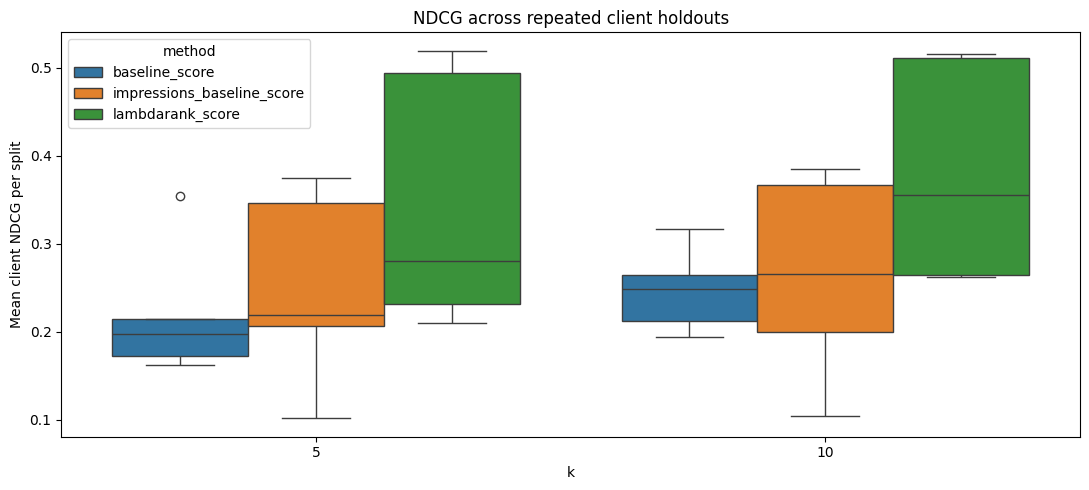

method,split_seed,k,baseline_score,impressions_baseline_score,lambdarank_score,lambdarank_minus_rule,lambdarank_minus_impressions
0,11,5,0.214330,0.207230,0.209959,-0.004371,0.002729
1,11,10,0.212344,0.199814,0.261800,0.049456,0.061986
2,23,5,0.162546,0.101752,0.232103,0.069556,0.130351
3,23,10,0.193604,0.104310,0.264826,0.071222,0.160516
4,42,5,0.197687,0.218794,0.280003,0.082316,0.061209
5,42,10,0.248911,0.265866,0.355012,0.106101,0.089147
6,61,5,0.354304,0.374671,0.519440,0.165136,0.144768
7,61,10,0.316873,0.384886,0.515385,0.198512,0.130499
8,97,5,0.172489,0.345930,0.494150,0.321662,0.148221
9,97,10,0.264465,0.366862,0.511671,0.247206,0.144808


In [15]:
metrics_summary = (
    metrics_detail.groupby(["method", "k"])["ndcg"]
    .agg(
        mean_ndcg="mean",
        std_ndcg="std",
        median_ndcg="median",
        p10_ndcg=lambda s: s.quantile(0.10),
        p90_ndcg=lambda s: s.quantile(0.90),
        clients_evaluated="count",
    )
    .reset_index()
    .sort_values(["k", "mean_ndcg"], ascending=[True, False])
)
display(metrics_summary)

split_summary = (
    metrics_detail.groupby(["split_seed", "method", "k"])["ndcg"]
    .mean().reset_index(name="mean_client_ndcg")
)
plt.figure(figsize=(11, 5))
sns.boxplot(data=split_summary, x="k", y="mean_client_ndcg", hue="method")
plt.title("NDCG across repeated client holdouts")
plt.ylabel("Mean client NDCG per split")
plt.tight_layout()
plt.show()

paired = split_summary.pivot_table(index=["split_seed", "k"], columns="method", values="mean_client_ndcg").reset_index()
if {"lambdarank_score", "baseline_score"}.issubset(paired.columns):
    paired["lambdarank_minus_rule"] = paired["lambdarank_score"] - paired["baseline_score"]
if {"lambdarank_score", "impressions_baseline_score"}.issubset(paired.columns):
    paired["lambdarank_minus_impressions"] = paired["lambdarank_score"] - paired["impressions_baseline_score"]
display(paired)

## 12. Build evidence-based recommendation eligibility

Ranking alone is not enough for a HIGH label. Recommendations must have reliable feature coverage, a minimum level of observed impressions, and evidence that the page had a meaningful negative trend in the historical feature windows. The rule uses **features only**, not target-window outcomes or relevance labels.

The target period is retained in the held-out queue for retrospective evaluation only; it must not be used as a live recommendation feature.

In [16]:
def add_recommendation_evidence(frame):
    out = frame.copy()
    out["recommendation_eligible"] = (
        (out["feat_active_days_60_90"] >= MIN_RECOMMENDATION_FEATURE_DAYS) &
        (out["feat_imp_60_90"] >= MIN_RECOMMENDATION_FEATURE_IMPRESSIONS) &
        out["feat_imp_log_ratio"].notna() &
        out["feat_pos_60_90"].notna()
    )
    out["historical_decline_evidence"] = out["feat_imp_log_ratio"] <= np.log(0.80)
    out["high_priority_evidence"] = (
        out["recommendation_eligible"] & out["historical_decline_evidence"]
    )
    return out

last_split_test = add_recommendation_evidence(last_split_test)
last_split_test["model_rank"] = last_split_test.groupby("client_hash_id")["lambdarank_score"].rank(method="first", ascending=False).astype(int)
last_split_test["baseline_rank"] = last_split_test.groupby("client_hash_id")["baseline_score"].rank(method="first", ascending=False).astype(int)
last_split_test["priority_tier"] = np.select(
    [
        last_split_test["recommendation_eligible"] &
        last_split_test["high_priority_evidence"] &
        (last_split_test["model_rank"] <= 5),
        last_split_test["recommendation_eligible"] &
        (last_split_test["model_rank"] <= 15),
        last_split_test["recommendation_eligible"],
    ],
    ["HIGH", "MEDIUM", "LOW"],
    default="NOT_ELIGIBLE",
)
display(last_split_test["priority_tier"].value_counts(dropna=False).to_frame("rows"))

,rows
priority_tier,
LOW,7835
NOT_ELIGIBLE,447
MEDIUM,75
HIGH,6


## 13. Join metadata and query signals into the recommendation queue

Metadata and query signals are joined after model prediction. Query fields can explain demand concentration or limited query visibility, but they remain context-only until their as-of date is verified. Left joins preserve recommendations without metadata.

In [17]:
queue = last_split_test.copy()
if not metadata_df.empty and "content_hash_id" in metadata_df.columns:
    queue = queue.merge(metadata_df, on="content_hash_id", how="left", validate="many_to_one")
if not qsignals_df.empty and "content_hash_id" in qsignals_df.columns:
    queue = queue.merge(qsignals_df, on="content_hash_id", how="left", validate="many_to_one")

def make_action(row):
    actions = []
    if not row.get("recommendation_eligible", False):
        return "Insufficient reliable historical evidence; monitor or validate data coverage before prioritizing."
    if row.get("historical_decline_evidence", False):
        actions.append("Investigate the historical impression decline; refresh only if content is outdated or incomplete")
    pos = row.get("feat_pos_60_90", np.nan)
    if pd.notna(pos) and 4 <= pos <= 20:
        actions.append("Review search intent, title/meta description, and missing subtopics")
    ctr = row.get("feat_ctr_60_90", np.nan)
    if pd.notna(ctr) and ctr < 0.02:
        actions.append("Review query-level CTR and snippet relevance before changing content")
    rare = row.get("rare_share", np.nan)
    if pd.notna(rare) and rare > 0.5:
        actions.append("Inspect long-tail query coverage and whether important subtopics are missing")
    return "; ".join(actions) if actions else "Review page and query evidence before deciding on a refresh"

queue["suggested_action"] = queue.apply(make_action, axis=1)
queue_cols = [
    "client_hash_id", "content_hash_id", "model_rank", "priority_tier",
    "recommendation_eligible", "high_priority_evidence", "historical_decline_evidence",
    "lambdarank_score", "baseline_rank", "baseline_score",
    "target_trend_pct", "target_imp_prev30", "target_imp_last30",
    "target_observed_days_prev30", "target_observed_days_last30",
    "feat_imp_60_90", "feat_imp_90_120", "feat_imp_log_ratio",
    "feat_active_days_60_90", "feat_pos_60_90", "feat_ctr_60_90",
    "suggested_action"
]
metadata_candidates = [
    "title", "content_title", "page_title", "meta_title",
    "url", "content_url", "canonical_url", "page_url",
    "published_at", "publish_date", "published_date", "created_at", "first_published_at"
]
query_candidates = [
    "visible_queries", "rare_share", "anon_share",
    "top_query_impressions", "kept_query_impressions", "top_query_share"
]
queue_cols += [c for c in metadata_candidates + query_candidates if c in queue.columns]
queue_cols = list(dict.fromkeys([c for c in queue_cols if c in queue.columns]))
display(queue.sort_values(["client_hash_id", "model_rank"]).groupby("client_hash_id", sort=False).head(5)[queue_cols].head(30))

,client_hash_id,content_hash_id,model_rank,priority_tier,recommendation_eligible,high_priority_evidence,historical_decline_evidence,lambdarank_score,baseline_rank,baseline_score,...,feat_active_days_60_90,feat_pos_60_90,feat_ctr_60_90,suggested_action,visible_queries,rare_share,anon_share,top_query_impressions,kept_query_impressions,top_query_share
3586,client_08a6a72ff48e62c0,content_b15bb01e85013477,1,MEDIUM,True,False,False,3.239380,1204,46.902101,...,30,7.848537,0.000000,"Review search intent, title/meta description, ...",50.0,0.058586,0.706510,512.0,2093.0,0.244625
3381,client_08a6a72ff48e62c0,content_a7296d5fc22a04ac,2,MEDIUM,True,False,False,3.185243,1630,44.444980,...,30,6.751213,0.000000,"Review search intent, title/meta description, ...",24.0,0.011270,0.736539,111.0,1007.0,0.110228
2924,client_08a6a72ff48e62c0,content_90ff4e763f53db71,3,MEDIUM,True,False,False,3.009784,1332,46.164964,...,30,7.340549,0.000000,"Review search intent, title/meta description, ...",14.0,0.037818,0.917177,68.0,382.0,0.178010
1191,client_08a6a72ff48e62c0,content_3ccf7b567d9deea3,4,MEDIUM,True,False,False,2.976977,1726,43.953556,...,30,5.963756,0.000000,"Review search intent, title/meta description, ...",17.0,0.069099,0.697425,155.0,544.0,0.284926
262,client_08a6a72ff48e62c0,content_0c82ab20843cc5f3,5,MEDIUM,True,False,False,2.792704,1455,45.439873,...,30,6.913973,0.000000,"Review search intent, title/meta description, ...",17.0,0.217178,0.691514,61.0,354.0,0.172316
5194,client_08d2847f24cf89c1,content_7c7f399ab41e3f41,1,MEDIUM,True,False,False,-1.121235,13,9.263333,...,23,44.469899,0.000000,Review query-level CTR and snippet relevance b...,7.0,0.277865,0.480377,64.0,154.0,0.415584
5196,client_08d2847f24cf89c1,content_842d54dbd6470483,2,MEDIUM,True,False,False,-1.596524,10,23.846154,...,25,10.531459,0.000000,"Review search intent, title/meta description, ...",1.0,0.047319,0.826498,40.0,40.0,1.000000
5192,client_08d2847f24cf89c1,content_60576ee1b4d36202,3,MEDIUM,True,False,False,-1.703496,11,22.788462,...,29,25.526047,0.003817,Review query-level CTR and snippet relevance b...,2.0,0.130935,0.768345,57.0,70.0,0.814286
5201,client_08d2847f24cf89c1,content_ff0212c6580d70db,4,NOT_ELIGIBLE,False,False,True,-1.826628,7,37.459190,...,21,10.088662,0.000000,Insufficient reliable historical evidence; mon...,3.0,0.027322,0.770492,48.0,74.0,0.648649
5193,client_08d2847f24cf89c1,content_6b26d9cd3949959d,5,MEDIUM,True,False,False,-1.983248,12,9.615385,...,28,30.515379,0.000000,Review query-level CTR and snippet relevance b...,5.0,0.247458,0.598305,30.0,91.0,0.329670


## 14. Inspect model/baseline disagreements and feature importance

,client_hash_id,content_hash_id,model_rank,baseline_rank,rank_shift_model_minus_baseline,relevance,target_trend_pct,lambdarank_score,baseline_score
70010,client_08a6a72ff48e62c0,content_759d035a810b245b,5110,91,5019,3,-0.646264,-2.992534,76.108466
69230,client_08a6a72ff48e62c0,content_134da73643e6fc29,4996,45,4951,2,-0.510000,-2.809622,82.250770
747,client_08a6a72ff48e62c0,content_e736d94ae0776853,4992,41,4951,3,-0.653846,-2.807051,82.432276
76234,client_08a6a72ff48e62c0,content_601f68964b8ebb6e,5020,73,4947,2,-0.429091,-2.835092,77.377327
70344,client_08a6a72ff48e62c0,content_aa2951f9f8a343e0,5108,170,4938,0,-0.134387,-2.988713,69.834247
71033,client_08a6a72ff48e62c0,content_583879e1e4843542,4939,19,4920,3,-0.627083,-2.747576,86.791771
26610,client_08a6a72ff48e62c0,content_28313fada49ec609,273,5162,-4889,0,-0.168003,-0.133712,1.495953
70552,client_08a6a72ff48e62c0,content_e7b9329f05d0868f,5151,265,4886,0,-0.170316,-3.117981,61.238633
69863,client_08a6a72ff48e62c0,content_8de8876c55492aae,4951,70,4881,0,-0.077922,-2.758318,77.751777
69754,client_08a6a72ff48e62c0,content_ec14d7f027c152f6,5134,256,4878,1,-0.317305,-3.061532,61.611237


,importance
feat_pos_volatility_60_90,1269
feat_imp_log_ratio,1163
log_feat_imp_60_90,1153
feat_pos_90_120,1105
feat_pos_60_90,1094
feat_position_change,975
log_feat_imp_90_120,940
feat_ctr_90_120,669
feat_ctr_60_90,586
feat_active_days_90_120,520


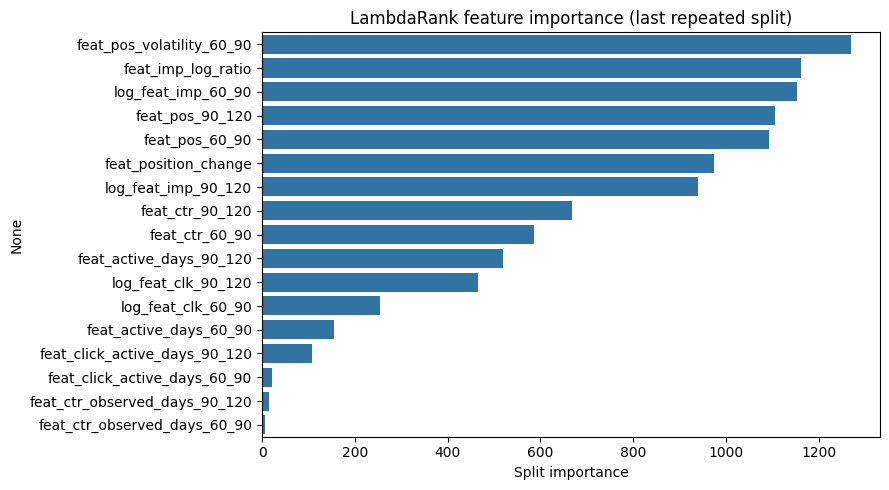

In [18]:
comparison = last_split_test.copy()
comparison["rank_shift_model_minus_baseline"] = comparison["model_rank"] - comparison["baseline_rank"]
display(comparison.reindex(comparison["rank_shift_model_minus_baseline"].abs().sort_values(ascending=False).index)[
    [c for c in ["client_hash_id", "content_hash_id", "model_rank", "baseline_rank",
                 "rank_shift_model_minus_baseline", "relevance", "target_trend_pct",
                 "lambdarank_score", "baseline_score"] if c in comparison.columns]
].head(30))

importance = last_split_importance
display(importance.to_frame())
plt.figure(figsize=(9, 5))
sns.barplot(x=importance.values, y=importance.index)
plt.title("LambdaRank feature importance (last repeated split)")
plt.xlabel("Split importance")
plt.tight_layout()
plt.show()

## 15. Train the final model and export artifacts

After repeated evaluation, fit a final model on all eligible rows, using the same training-only stratified cap policy if required. This model is for future scoring experiments; do not use it to report held-out evaluation metrics. The held-out queue below is from the final seed's test clients and remains out-of-client for that split.

In [19]:
final_frame_full = sort_group_frame(eligible)
final_frame, final_sampling_report = stratified_cap_training_groups(final_frame_full, seed=2026)
final_frame = sort_group_frame(final_frame)
final_imputer = SimpleImputer(strategy="median", keep_empty_features=True)
X_final = final_imputer.fit_transform(final_frame[feature_cols].replace([np.inf, -np.inf], np.nan))
y_final = final_frame["relevance"].to_numpy(dtype=int)
final_groups = group_sizes_for(final_frame)

final_ranker = LGBMRanker(
    objective="lambdarank",
    metric="ndcg",
    n_estimators=350,
    learning_rate=0.04,
    num_leaves=31,
    min_child_samples=25,
    subsample=0.85,
    colsample_bytree=0.85,
    reg_lambda=1.0,
    random_state=2026,
    n_jobs=-1,
    label_gain=[0, 1, 3, 7, 15],
    verbosity=-1,
)
final_ranker.fit(X_final, y_final, group=final_groups)

OUT_METRICS = "flyrank_stage2_1_ndcg_summary.csv"
OUT_DETAIL = "flyrank_stage2_1_ndcg_per_client_split.csv"
OUT_SPLITS = "flyrank_stage2_1_split_diagnostics.csv"
OUT_QUEUE = "flyrank_stage2_1_heldout_recommendation_queue.csv"
OUT_IMPORTANCE = "flyrank_stage2_1_feature_importance.csv"
OUT_COVERAGE = "flyrank_stage2_1_gsc_coverage_audit.csv"
OUT_CTR = "flyrank_stage2_1_ctr_missingness_audit.csv"
OUT_MODEL = "flyrank_stage2_1_lambdarank_model.joblib"

metrics_summary.to_csv(OUT_METRICS, index=False)
metrics_detail.to_csv(OUT_DETAIL, index=False)
split_report_df.to_csv(OUT_SPLITS, index=False)
queue.sort_values(["client_hash_id", "model_rank"])[queue_cols].to_csv(OUT_QUEUE, index=False)
importance.to_frame().to_csv(OUT_IMPORTANCE)
availability_audit.to_csv(OUT_COVERAGE, index=False)
ctr_audit.to_csv(OUT_CTR, index=False)

joblib.dump({
    "ranker": final_ranker,
    "imputer": final_imputer,
    "feature_cols": feature_cols,
    "label_definition": grade_names,
    "grouping": "client_hash_id",
    "feature_window": "days 60-120 before latest report date",
    "target_definition": "latest 30-day impression change versus preceding 30 days",
    "coverage_policy": {
        "min_target_observed_days_per_30d_window": MIN_TARGET_OBSERVED_DAYS,
        "min_feature_observed_days_per_30d_window": MIN_FEATURE_OBSERVED_DAYS,
        "min_previous_target_impressions": MIN_PREV_TARGET_IMPRESSIONS,
    },
    "recommendation_policy": {
        "min_feature_days": MIN_RECOMMENDATION_FEATURE_DAYS,
        "min_feature_impressions": MIN_RECOMMENDATION_FEATURE_IMPRESSIONS,
        "high_priority_requires_historical_decline_evidence": True,
    },
    "random_seeds": RANDOM_SEEDS,
    "query_signals_used_as_model_features": False,
    "warning": "Historical decline severity is a refresh-priority proxy, not causal refresh-uplift probability."
}, OUT_MODEL)

print("Saved artifacts:")
for filename in [OUT_METRICS, OUT_DETAIL, OUT_SPLITS, OUT_QUEUE, OUT_IMPORTANCE, OUT_COVERAGE, OUT_CTR, OUT_MODEL]:
    print(" -", filename)

try:
    from google.colab import files as colab_files
    for filename in [OUT_METRICS, OUT_DETAIL, OUT_SPLITS, OUT_QUEUE, OUT_IMPORTANCE, OUT_COVERAGE, OUT_CTR, OUT_MODEL]:
        colab_files.download(filename)
except Exception as exc:
    print("Automatic browser downloads unavailable; files remain in the Colab runtime:", exc)

Saved artifacts:
 - flyrank_stage2_1_ndcg_summary.csv
 - flyrank_stage2_1_ndcg_per_client_split.csv
 - flyrank_stage2_1_split_diagnostics.csv
 - flyrank_stage2_1_heldout_recommendation_queue.csv
 - flyrank_stage2_1_feature_importance.csv
 - flyrank_stage2_1_gsc_coverage_audit.csv
 - flyrank_stage2_1_ctr_missingness_audit.csv
 - flyrank_stage2_1_lambdarank_model.joblib


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 16. Stage 2.1 validation checklist and interpretation

Before moving to Stage 3:

1. Review GSC availability and duplicate-key audits. Resolve duplicate daily keys before training.
2. Confirm that the coverage thresholds leave enough clients and do not disproportionately exclude particular clients.
3. Inspect CTR missingness and the stable log-ratio distribution.
4. Check that every split has disjoint train/test clients and that test rows were not capped.
5. Compare NDCG means **and distributions** across repeated client splits; do not assume LambdaRank wins.
6. Inspect HIGH recommendations and verify that each meets the feature coverage, volume, and historical-decline evidence rules.
7. Check metadata/query join coverage. Query signals are context only until their date alignment is known.
8. The current warehouse snapshot in the previous run ended on 2026-06-30. Recheck the current max date after rerunning.

### Known assumptions and limitations
- `gsc_data_available` is treated as the authoritative row-level availability flag. Confirm the dataset's exact semantics.
- The observed-day threshold of 15 days per 30-day window is configurable and should be justified by the audit.
- A content-day without a row is not counted as an observed zero. This is deliberately conservative.
- Impression and click totals are scaled to a 30-observed-day equivalent before comparing windows, reducing but not eliminating bias from uneven content-day coverage.
- Query signal fields may summarize a separate 90-day window and are not model features until their cutoff is verified.
- The final target is observed decline, not causal refresh uplift.
- This notebook has been checked for Python syntax and notebook structure only. Warehouse-dependent SQL, row counts, join coverage, model metrics, and exported artifacts must be verified by running it with authenticated access.